# Capital de Vasicek: qué tan bien aproxima la fórmula de un factor a una cartera real

**Perfil:** Riesgo de crédito (estrategia y portafolio)  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

La fórmula de un factor (ASRF) da el capital al 99,9 % en forma cerrada, pero supone una cartera infinitamente granular, homogénea y con parámetros conocidos. ¿Cuánto se equivoca cuando la cartera es finita, heterogénea y la correlación se **estima** con pocos años de historia?

## Recorrido

1. La fórmula cerrada y su verificación contra simulación en el caso ideal.
2. **Versión 1:** aplicarla tal cual a una cartera finita.
3. **Tres diagnósticos:** granularidad (¿cómo escala el desvío con N?), heterogeneidad de PD (desigualdad de Jensen) e incertidumbre en $\rho$.
4. **Versión 2:** estimación de $(\mathrm{PD},\rho)$ por máxima verosimilitud sobre una serie de tasas de default, y el colchón necesario para tener cobertura.
5. Pruebas, sensibilidad y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy.stats import norm
from scipy.optimize import minimize, brentq
from scipy.integrate import quad

## 2. La fórmula y su verificación en el caso ideal

Con un factor sistémico $Y\sim N(0,1)$, la PD condicional es
$$p(y)=\Phi\!\Big(\frac{\Phi^{-1}(\mathrm{PD})-\sqrt\rho\,y}{\sqrt{1-\rho}}\Big).$$
En una cartera infinitamente granular la tasa de pérdida es $\mathrm{LGD}\cdot p(Y)$, y su cuantil $q$ se obtiene con $y=\Phi^{-1}(1-q)$. El **capital** (pérdida inesperada) es ese cuantil menos la pérdida esperada:
$$K=\mathrm{LGD}\Big[\Phi\!\Big(\tfrac{\Phi^{-1}(\mathrm{PD})+\sqrt\rho\,\Phi^{-1}(q)}{\sqrt{1-\rho}}\Big)-\mathrm{PD}\Big].$$

In [2]:
Q = 0.999

def pd_condicional(pd_i, rho, y):
    return norm.cdf((norm.ppf(pd_i) - np.sqrt(rho) * y) / np.sqrt(1 - rho))

def capital_asrf(pd_i, rho, lgd=0.45, q=Q):
    return lgd * (norm.cdf((norm.ppf(pd_i) + np.sqrt(rho) * norm.ppf(q)) / np.sqrt(1 - rho)) - pd_i)

def capital_mc(pd_i, rho, n, lgd=0.45, q=Q, sims=400_000, seed=0):
    rng = np.random.default_rng(seed)
    y = rng.standard_normal(sims)
    defaults = rng.binomial(n, pd_condicional(pd_i, rho, y))
    perdida = lgd * defaults / n
    return np.quantile(perdida, q) - lgd * pd_i

PD0, RHO0, LGD0 = 0.02, 0.15, 0.45
K_ASRF = capital_asrf(PD0, RHO0, LGD0)
print(f"K (formula) = {K_ASRF:.5f}   K (MC, N=1.000.000 deudores) = {capital_mc(PD0, RHO0, 1_000_000):.5f}")

K (formula) = 0.07035   K (MC, N=1.000.000 deudores) = 0.07104


## 3. Versión 1: aplicar la fórmula a una cartera finita

Se compara la fórmula con la simulación para distintos tamaños de cartera $N$ (deudores homogéneos).

In [3]:
Ns = [20, 50, 100, 250, 500, 1000, 5000, 50_000]
filas = []
for n in Ns:
    filas.append({"N": n, "K_ASRF": K_ASRF, "K_MC": capital_mc(PD0, RHO0, n, lgd=LGD0, seed=n)})
gran = pd.DataFrame(filas).set_index("N")
gran["razon_MC/ASRF"] = gran["K_MC"] / gran["K_ASRF"]
gran["desvio_%"] = (gran["razon_MC/ASRF"] - 1) * 100
gran.round(5)

,K_ASRF,K_MC,razon_MC/ASRF,desvio_%
N,,,,
20,0.0703,0.1035,1.4713,47.1257
50,0.0703,0.0900,1.2793,27.9354
100,0.0703,0.0810,1.1514,15.1418
250,0.0703,0.0738,1.0491,4.9070
500,0.0703,0.0720,1.0235,2.3483
1000,0.0703,0.0707,1.0043,0.4293
5000,0.0703,0.0708,1.0069,0.6851
50000,0.0703,0.0708,1.0063,0.6340


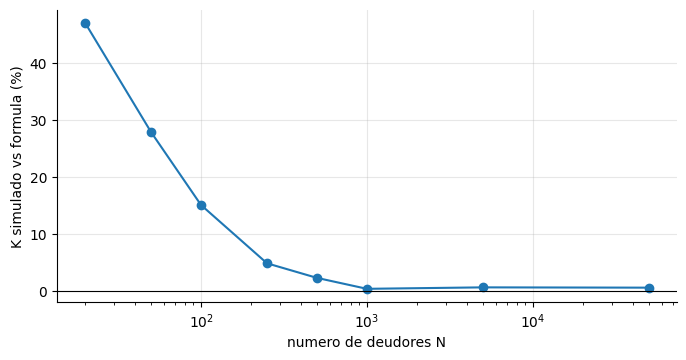

Ruido de Monte Carlo del cuantil al 99.9% (8 semillas, N=50.000): media -0.16%, desvio 1.31%.
Lectura:
  Con N=20 el capital simulado supera a la formula en +47.1%; con N=50,000 la diferencia es +0.63%.
  Esa diferencia residual de N grande es del orden del error de Monte Carlo (1.31% de desvio entre semillas): no es un sesgo de la formula.


In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogx(gran.index, gran["desvio_%"], "o-"); ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("numero de deudores N"); ax.set_ylabel("K simulado vs formula (%)"); plt.show()
ruido = np.array([capital_mc(PD0, RHO0, 50_000, lgd=LGD0, seed=100 + i) for i in range(8)]) / K_ASRF - 1
print(f"Ruido de Monte Carlo del cuantil al 99.9% (8 semillas, N=50.000): media {ruido.mean() * 100:+.2f}%, desvio {ruido.std() * 100:.2f}%.")
print("Lectura:")
print(f"  Con N={Ns[0]} el capital simulado supera a la formula en {gran['desvio_%'].iloc[0]:+.1f}%; con N={Ns[-1]:,} la diferencia es {gran['desvio_%'].iloc[-1]:+.2f}%.")
print(f"  Esa diferencia residual de N grande es del orden del error de Monte Carlo ({ruido.std() * 100:.2f}% de desvio entre semillas): no es un sesgo de la formula.")

### 3.1 Diagnóstico 1: ¿el desvío por granularidad escala como $1/N$?

La teoría del ajuste por granularidad (Gordy) dice que el exceso de capital por concentración idiosincrática es de orden $1/N$. Se comprueba ajustando $\text{razón}-1=c/N$.

In [5]:
exceso = gran["razon_MC/ASRF"] - 1
sub = exceso[gran.index <= 1000]
X = 1.0 / sub.index.to_numpy()
c_hat = float((X * sub.to_numpy()).sum() / (X ** 2).sum())                # regresion por el origen
ajuste = c_hat * X
r2 = 1 - ((sub.to_numpy() - ajuste) ** 2).sum() / ((sub.to_numpy() - sub.mean()) ** 2).sum()
pendiente_loglog = np.polyfit(np.log(sub.index.to_numpy()), np.log(sub.to_numpy()), 1)[0]
print(f"Ajuste exceso = c/N con N<=1000: c = {c_hat:.2f}, R2 = {r2:.3f}")
print(f"Pendiente log-log del exceso contra N: {pendiente_loglog:.2f}  (teoria: -1)")

Ajuste exceso = c/N con N<=1000: c = 10.23, R2 = 0.941
Pendiente log-log del exceso contra N: -1.16  (teoria: -1)


### 3.2 Diagnóstico 2: heterogeneidad de PD (desigualdad de Jensen)

La fórmula supone **la misma PD** para todos. Con una cartera de PD distintas y la misma PD media, el capital del modelo de un factor (infinitamente granular) es
$$K_{\text{het}}=\mathrm{LGD}\cdot\frac1N\sum_i\big[p_i(y_q)-\mathrm{PD}_i\big],$$
y no coincide con la fórmula evaluada en la PD media, porque $p(y)$ es **no lineal** en la PD.

In [6]:
def capital_het(pds, rho, lgd=LGD0, q=Q, pesos=None):
    w = np.full(len(pds), 1 / len(pds)) if pesos is None else pesos / pesos.sum()
    y = norm.ppf(1 - q)
    return float(lgd * (w * (pd_condicional(pds, rho, y) - pds)).sum())

rng = np.random.default_rng(11)
filas = []
for cv in (0.0, 0.5, 1.0, 1.5, 2.0):
    if cv == 0:
        pds = np.full(20_000, PD0)
    else:
        sd = cv * PD0
        a = PD0 * (PD0 * (1 - PD0) / sd ** 2 - 1); b = (1 - PD0) * (PD0 * (1 - PD0) / sd ** 2 - 1)
        pds = rng.beta(a, b, 20_000); pds = pds * PD0 / pds.mean()            # misma PD media
    k_het = capital_het(pds, RHO0)
    filas.append({"cv_de_la_PD": cv, "PD_media": pds.mean(), "K_heterogeneo": k_het, "K_formula(PD media)": capital_asrf(pds.mean(), RHO0, LGD0)})
het = pd.DataFrame(filas).set_index("cv_de_la_PD")
het["desvio_%"] = (het["K_formula(PD media)"] / het["K_heterogeneo"] - 1) * 100
het.round(5)

,PD_media,K_heterogeneo,K_formula(PD media),desvio_%
cv_de_la_PD,,,,
0.0000,0.0200,0.0703,0.0703,-0.0000
0.5000,0.0200,0.0676,0.0703,4.0652
1.0000,0.0200,0.0608,0.0703,15.6913
1.5000,0.0200,0.0522,0.0703,34.8721
2.0000,0.0200,0.0441,0.0703,59.6357


In [7]:
print("Lectura:")
print(f"  Con cv(PD)=1.0 la formula evaluada en la PD media {'SUBESTIMA' if het.loc[1.0, 'desvio_%'] < 0 else 'SOBRESTIMA'} el capital en {abs(het.loc[1.0, 'desvio_%']):.1f}%; con cv=2.0, en {abs(het.loc[2.0, 'desvio_%']):.1f}%.")
print(f"  Como el capital heterogeneo queda {'por debajo' if het.loc[1.0, 'desvio_%'] > 0 else 'por encima'} del de la PD media, la funcion PD -> capital es {'concava' if het.loc[1.0, 'desvio_%'] > 0 else 'convexa'} en este rango (desigualdad de Jensen): promediar la PD antes de aplicar una funcion no lineal introduce sesgo.")

Lectura:
  Con cv(PD)=1.0 la formula evaluada en la PD media SOBRESTIMA el capital en 15.7%; con cv=2.0, en 59.6%.
  Como el capital heterogeneo queda por debajo del de la PD media, la funcion PD -> capital es concava en este rango (desigualdad de Jensen): promediar la PD antes de aplicar una funcion no lineal introduce sesgo.


### 3.3 Diagnóstico 3: $\rho$ y PD son parámetros **estimados**

En la práctica $\rho$ no se conoce: se estima de una **serie histórica de tasas de default**. Con el modelo de un factor, la tasa de default anual $x_t$ de una cartera grande sigue la **distribución de Vasicek**:
$$f(x)=\sqrt{\tfrac{1-\rho}{\rho}}\;\frac{\varphi(u)}{\varphi(\Phi^{-1}(x))},\qquad u=\frac{\sqrt{1-\rho}\,\Phi^{-1}(x)-\Phi^{-1}(\mathrm{PD})}{\sqrt\rho}.$$
Se implementa la verosimilitud y se **verifica que la densidad sea una densidad** (integra 1 y tiene media igual a la PD).

In [8]:
def logdens_vasicek(x, pd_i, rho):
    xq = norm.ppf(x); u = (np.sqrt(1 - rho) * xq - norm.ppf(pd_i)) / np.sqrt(rho)
    return 0.5 * np.log((1 - rho) / rho) - 0.5 * u ** 2 + 0.5 * xq ** 2

for pd_i, rho in ((0.02, 0.15), (0.05, 0.08), (0.01, 0.30)):
    integral = quad(lambda x: np.exp(logdens_vasicek(x, pd_i, rho)), 0, 1, limit=200)[0]
    media = quad(lambda x: x * np.exp(logdens_vasicek(x, pd_i, rho)), 0, 1, limit=200)[0]
    print(f"PD={pd_i}, rho={rho}: integral = {integral:.5f}, media = {media:.5f} (debe ser {pd_i})")

PD=0.02, rho=0.15: integral = 1.00000, media = 0.02000 (debe ser 0.02)
PD=0.05, rho=0.08: integral = 1.00000, media = 0.05000 (debe ser 0.05)


PD=0.01, rho=0.3: integral = 1.00000, media = 0.01000 (debe ser 0.01)


In [9]:
def estimar_mle(dr, n_deudores):
    x = np.clip(dr, 0.5 / n_deudores, 1 - 0.5 / n_deudores)
    def nll(theta):
        pd_i, rho = 1 / (1 + np.exp(-theta[0])), 1 / (1 + np.exp(-theta[1]))
        return -logdens_vasicek(x, pd_i, rho).sum()
    mejor = None
    for a0, b0 in ((np.log(x.mean() / (1 - x.mean())), -1.5), (np.log(x.mean() / (1 - x.mean())), -3.0)):
        r = minimize(nll, [a0, b0], method="Nelder-Mead", options={"xatol": 1e-6, "fatol": 1e-9, "maxiter": 600})
        if mejor is None or r.fun < mejor.fun: mejor = r
    return 1 / (1 + np.exp(-mejor.x[0])), 1 / (1 + np.exp(-mejor.x[1]))

def simular_serie(T, n_deudores, rng, pd_i=PD0, rho=RHO0):
    y = rng.standard_normal(T)
    return rng.binomial(n_deudores, pd_condicional(pd_i, rho, y)) / n_deudores

# primero: con una serie larga el estimador recupera los parametros
rl = np.random.default_rng(1)
dr_larga = simular_serie(2000, 20_000, rl)
pd_hat, rho_hat = estimar_mle(dr_larga, 20_000)
print(f"Serie de 2.000 anios: PD estimada = {pd_hat:.4f} (verdadera {PD0}), rho estimada = {rho_hat:.4f} (verdadera {RHO0})")

Serie de 2.000 anios: PD estimada = 0.0204 (verdadera 0.02), rho estimada = 0.1548 (verdadera 0.15)


Con una serie larguísima el estimador funciona. Pero una cartera real tiene **10–25 años** de historia. Se repite el ejercicio muchas veces con series cortas y se mide qué tan lejos queda el capital estimado del verdadero.

In [10]:
def experimento(T, R=200, n_deudores=20_000, seed=0):
    rg = np.random.default_rng(seed)
    ks = np.empty(R); rhos = np.empty(R)
    for r in range(R):
        dr = simular_serie(T, n_deudores, rg)
        p, rr = estimar_mle(dr, n_deudores)
        ks[r], rhos[r] = capital_asrf(p, rr, LGD0), rr
    return ks, rhos

resultados = {}
filas = []
for T in (10, 20, 40, 100):
    ks, rhos = experimento(T, seed=T)
    resultados[T] = ks
    razon = ks / K_ASRF
    filas.append({"T_anios": T, "rho_mediana": np.median(rhos), "K_mediana/K": np.median(razon), "P5": np.percentile(razon, 5), "P95": np.percentile(razon, 95),
                  "prob_subestimar": (ks < K_ASRF).mean(), "colchon_90%": np.percentile(K_ASRF / ks, 90)})
inc = pd.DataFrame(filas).set_index("T_anios")
inc.round(3)

,rho_mediana,K_mediana/K,P5,P95,prob_subestimar,colchon_90%
T_anios,,,,,,
10,0.1320,0.8620,0.3460,2.0270,0.6000,2.1200
20,0.1400,0.9280,0.4960,1.5050,0.6100,1.7790
40,0.1480,0.9540,0.6310,1.4580,0.5500,1.4260
100,0.1520,1.0160,0.7530,1.2540,0.4650,1.2500


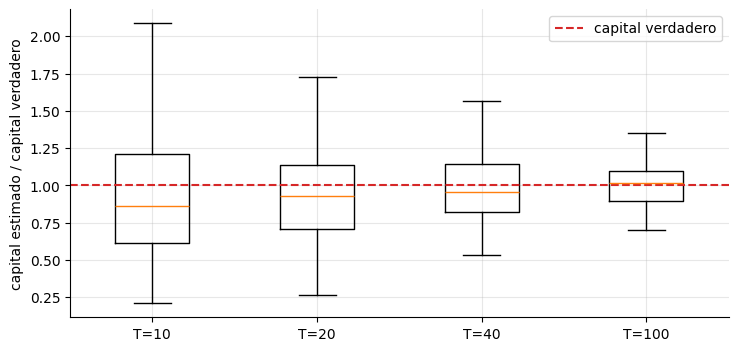

Lectura:
  La rho estimada tiene sesgo a la baja con series cortas: mediana 0.132 con T=10 y 0.152 con T=100 (verdadera 0.15). Por eso subestimar el capital es mas probable que sobrestimarlo.
  Con T=10 anios, el capital estimado va de 0.35x a 2.03x el verdadero (P5-P95) y subestima en el 60% de los casos.
  Con T=100 anios el rango es 0.75x a 1.25x.
  Para tener 90% de probabilidad de NO subestimar con T=20 habria que multiplicar el capital estimado por 1.78.


In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4))
data = [resultados[T] / K_ASRF for T in resultados]
ax.boxplot(data, labels=[f"T={T}" for T in resultados], showfliers=False); ax.axhline(1, color="C3", ls="--", label="capital verdadero")
ax.set_ylabel("capital estimado / capital verdadero"); ax.legend(); plt.show()
print("Lectura:")
print(f"  La rho estimada tiene sesgo a la baja con series cortas: mediana {inc.loc[10, 'rho_mediana']:.3f} con T=10 y {inc.loc[100, 'rho_mediana']:.3f} con T=100 (verdadera {RHO0}). Por eso subestimar el capital es mas probable que sobrestimarlo.")
print(f"  Con T=10 anios, el capital estimado va de {inc.loc[10, 'P5']:.2f}x a {inc.loc[10, 'P95']:.2f}x el verdadero (P5-P95) y subestima en el {inc.loc[10, 'prob_subestimar']:.0%} de los casos.")
print(f"  Con T=100 anios el rango es {inc.loc[100, 'P5']:.2f}x a {inc.loc[100, 'P95']:.2f}x.")
print(f"  Para tener 90% de probabilidad de NO subestimar con T=20 habria que multiplicar el capital estimado por {inc.loc[20, 'colchon_90%']:.2f}.")

**Qué se aprende.** El error de estimación de $\rho$ **domina** al de granularidad en carteras grandes: con series cortas, la incertidumbre del capital es del orden de decenas por ciento, y es **asimétrica** (cola derecha). El colchón necesario para cobertura cae lentamente con más años de datos.

## 4. Versión 2: capital con parámetros estimados y colchón por incertidumbre

Se integran los tres ajustes sobre una cartera concreta (heterogénea, finita) para ver el orden de magnitud relativo de cada fuente de desvío.

In [12]:
# cartera concreta: 500 deudores, PD heterogeneas con media 2%, rho verdadera 0.15
rng = np.random.default_rng(21)
n_c = 500
sd = 1.0 * PD0
a = PD0 * (PD0 * (1 - PD0) / sd ** 2 - 1); b = (1 - PD0) * (PD0 * (1 - PD0) / sd ** 2 - 1)
pds_c = rng.beta(a, b, n_c); pds_c *= PD0 / pds_c.mean()

# verdad "simulada": factor unico, deudores heterogeneos, N finito
def capital_mc_het(pds, rho, lgd=LGD0, q=Q, sims=200_000, seed=0):
    rg = np.random.default_rng(seed)
    y = rg.standard_normal(sims)
    perdidas = np.zeros(sims)
    for lo in range(0, sims, 20_000):
        yy = y[lo:lo + 20_000, None]
        p = pd_condicional(pds[None, :], rho, yy)
        perdidas[lo:lo + 20_000] = lgd * (rg.random(p.shape) < p).mean(axis=1)
    return np.quantile(perdidas, q) - lgd * pds.mean()

k_verdad_c = capital_mc_het(pds_c, RHO0)
k_formula_c = capital_asrf(pds_c.mean(), RHO0, LGD0)
k_het_c = capital_het(pds_c, RHO0)
tabla = pd.DataFrame({"capital": [k_formula_c, k_het_c, k_verdad_c]},
                     index=["formula con PD media (v1)", "heterogeneo, infinitamente granular", "simulacion (heterogeneo + N=500)"])
tabla["vs_simulacion_%"] = (tabla["capital"] / k_verdad_c - 1) * 100
tabla.round(5)

,capital,vs_simulacion_%
formula con PD media (v1),0.0703,10.0908
"heterogeneo, infinitamente granular",0.0614,-3.9623
simulacion (heterogeneo + N=500),0.0639,0.0000


In [13]:
print("Lectura:")
print(f"  La formula con PD media queda {tabla.iloc[0, 1]:+.1f}% respecto de la simulacion de la cartera concreta.")
print(f"  Quitar solo la homogeneidad (heterogeneo infinitamente granular) la deja en {tabla.iloc[1, 1]:+.1f}%; el resto ({tabla.iloc[2, 1] - tabla.iloc[1, 1]:+.1f} pts) es la granularidad de N=500.")
err_jensen = tabla.iloc[0, 1] - tabla.iloc[1, 1]          # error de la formula por ignorar la heterogeneidad
err_gran = tabla.iloc[1, 1] - tabla.iloc[2, 1]            # error del modelo infinitamente granular por ignorar N finito
print(f"  Efecto sobre la formula de ignorar la heterogeneidad: {err_jensen:+.1f} pts (la sobrestima); de ignorar el N finito: {err_gran:+.1f} pts (la subestima). Tienen signos opuestos y se compensan en parte (neto {err_jensen + err_gran:+.1f} pts).")
print(f"  Frente a eso, la incertidumbre por estimar rho con T=20 anios es de {(inc.loc[20, 'P95'] - inc.loc[20, 'P5']) * 100:.0f} puntos entre P5 y P95: el error de especificacion es pequeno comparado con el de estimacion.")

Lectura:
  La formula con PD media queda +10.1% respecto de la simulacion de la cartera concreta.
  Quitar solo la homogeneidad (heterogeneo infinitamente granular) la deja en -4.0%; el resto (+4.0 pts) es la granularidad de N=500.
  Efecto sobre la formula de ignorar la heterogeneidad: +14.1 pts (la sobrestima); de ignorar el N finito: -4.0 pts (la subestima). Tienen signos opuestos y se compensan en parte (neto +10.1 pts).
  Frente a eso, la incertidumbre por estimar rho con T=20 anios es de 101 puntos entre P5 y P95: el error de especificacion es pequeno comparado con el de estimacion.


## 5. Sensibilidad: capital contra $\rho$, PD y nivel de confianza

In [14]:
filas = []
for rho in (0.03, 0.08, 0.15, 0.24):
    for pd_i in (0.005, 0.02, 0.05):
        filas.append({"rho": rho, "PD": pd_i, "K": capital_asrf(pd_i, rho, LGD0)})
sens = pd.DataFrame(filas).pivot(index="rho", columns="PD", values="K")
sens.round(4)

PD,0.0050,0.0200,0.0500
rho,,,
0.0300,0.0064,0.0187,0.0360
0.0800,0.0149,0.0402,0.0724
0.1500,0.0281,0.0703,0.1186
0.2400,0.0480,0.1115,0.1756


In [15]:
filas = [{"q": q, "K": capital_asrf(PD0, RHO0, LGD0, q=q)} for q in (0.95, 0.99, 0.995, 0.999, 0.9995)]
niv = pd.DataFrame(filas).set_index("q")
print(niv.round(5).to_string())
print(f"\nElasticidad de K respecto de rho en rho={RHO0}: {(capital_asrf(PD0, RHO0 * 1.01, LGD0) / K_ASRF - 1) / 0.01:.2f} (un 1% mas de rho cambia K en ese %).")

            K
q            
0.9500 0.0190
0.9900 0.0385
0.9950 0.0477
0.9990 0.0703
0.9995 0.0805

Elasticidad de K respecto de rho en rho=0.15: 0.94 (un 1% mas de rho cambia K en ese %).


## 6. Pruebas automáticas

In [16]:
# 6.1 la formula coincide con la simulacion en el caso ideal (N muy grande), dentro del error de Monte Carlo
k_mc_grande = capital_mc(PD0, RHO0, 1_000_000)
assert abs(k_mc_grande / K_ASRF - 1) < 0.03
# 6.2 propiedades de la formula
assert capital_asrf(PD0, 1e-6, LGD0) < 1e-4                                  # sin correlacion no hay riesgo sistemico
assert capital_asrf(PD0, 0.3, LGD0) > capital_asrf(PD0, 0.1, LGD0) > capital_asrf(PD0, 0.03, LGD0)
assert capital_asrf(PD0, RHO0, LGD0, q=0.9999) > capital_asrf(PD0, RHO0, LGD0, q=0.999) > capital_asrf(PD0, RHO0, LGD0, q=0.99)
assert abs(capital_asrf(PD0, RHO0, 0.9) / capital_asrf(PD0, RHO0, 0.45) - 2) < 1e-12   # lineal en LGD
# 6.3 la granularidad: el capital simulado supera a la formula y el exceso decrece con N (escala ~1/N)
assert (gran["razon_MC/ASRF"].iloc[:-1] > 1 - 0.02).all()
assert gran["desvio_%"].iloc[0] > gran["desvio_%"].iloc[4] > gran["desvio_%"].iloc[-1] - 0.5
assert -1.5 < pendiente_loglog < -0.5, f"pendiente log-log {pendiente_loglog:.2f} lejos de -1"
assert r2 > 0.8
# 6.4 la densidad de Vasicek es una densidad
for pd_i, rho in ((0.02, 0.15), (0.05, 0.08)):
    assert abs(quad(lambda x: np.exp(logdens_vasicek(x, pd_i, rho)), 0, 1, limit=200)[0] - 1) < 1e-3
    assert abs(quad(lambda x: x * np.exp(logdens_vasicek(x, pd_i, rho)), 0, 1, limit=200)[0] - pd_i) < 1e-3
# 6.5 el MLE con serie larga recupera los parametros; con series cortas la incertidumbre es mayor y baja con T
assert abs(pd_hat / PD0 - 1) < 0.1 and abs(rho_hat / RHO0 - 1) < 0.15
anchos = (inc["P95"] - inc["P5"]).to_numpy()
assert np.all(np.diff(anchos) < 0), "la incertidumbre del capital debe bajar con mas anios de datos"
assert inc.loc[10, "prob_subestimar"] > 0.3
assert inc.loc[10, "rho_mediana"] < RHO0 and inc.loc[100, "rho_mediana"] > inc.loc[10, "rho_mediana"], "rho debe estar sesgada a la baja con series cortas"
assert abs(gran['desvio_%'].iloc[-1]) < 3 * ruido.std() * 100 + 0.5, 'el residual de N grande debe ser ruido de MC'
assert inc.loc[10, "colchon_90%"] > inc.loc[100, "colchon_90%"] > 0.95
# 6.6 la heterogeneidad produce el sesgo de Jensen con un signo definido y creciente con la dispersion
assert abs(het.loc[0.0, "desvio_%"]) < 1e-6
assert (het["desvio_%"].iloc[1:].abs().is_monotonic_increasing)
assert np.sign(het["desvio_%"].iloc[1:]).nunique() == 1
# 6.7 el capital heterogeneo infinitamente granular es consistente con la simulacion de la cartera concreta
assert abs(k_het_c / k_verdad_c - 1) < 0.25
assert err_jensen > 0 > err_gran, 'los dos errores de especificacion deben tener signos opuestos'
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Fórmula cerrada | Coincide con la simulación cuando la cartera es enorme y homogénea | Usarla como referencia, no como verdad |
| Granularidad | El exceso de capital por tamaño finito decrece con N y escala aproximadamente como 1/N | Aplicar un ajuste por granularidad en carteras de pocos cientos de deudores |
| Heterogeneidad | Promediar la PD antes de aplicar la fórmula es sesgado (Jensen), y el sesgo crece con la dispersión | Calcular con las PD individuales |
| Estimación de ρ | Con 10–25 años de datos la incertidumbre del capital es de decenas por ciento y asimétrica | Incluir un colchón por incertidumbre de parámetros |
| Jerarquía de errores | En una cartera de ~500 deudores el error de estimación supera al de especificación | Priorizar tiempo y datos en estimar bien ρ |

**Límites que no deben ocultarse**

- El modelo de un factor es una simplificación: ignora estructura sectorial, dependencia de cola y correlación entre PD y LGD.
- La serie de tasas de default se simula del propio modelo; las series reales tienen ciclos, tendencias y cambios de composición que violan la independencia entre años.
- La LGD es constante; con LGD estocástica y correlacionada con el ciclo el capital sube.
- El colchón calculado depende de que el modelo de estimación sea correcto; con un modelo mal especificado la cobertura real sería menor.
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.